# Topic 22 - Exploratory Data Analysis

## Knowing what to look for, before you know what you are looking for

Topic 20 wrangled five tables into one. Topic 21 taught you to build any chart correctly, once you already knew what to show. Both of those topics started from a **known question** - "which zone was most profitable," "did revenue grow" - and your job was to answer it accurately.

**Exploratory data analysis (EDA)** is what happens *before* you have a question like that. You have been handed a dataset nobody has looked at yet, and your job is to find out what is in it - what is typical, what is strange, what relates to what - before you know which of those things matters. This is a different skill from the last two topics, and it has its own discipline: a repeatable process for looking, a way of telling a real pattern from noise, and - because EDA is usually worth nothing if nobody else reads it - two distinct ways of writing up what you found.

This lesson uses two datasets. A new one - daily air-quality readings from nine sensors across Accra through 2023 - for the exploration itself, because EDA is only genuine practice on data you have not already seen the answers to. And the retail distributor from Topics 20-21, for the two report types this lesson teaches how to write, because a report about work has to be about work you actually did.

## Learning objectives

By the end of this lesson you should be able to:

- describe EDA as a repeatable loop - question, look, visualize, answer or ask a better question - rather than a checklist;
- turn a vague curiosity into a specific, answerable question;
- explore a single variable, a pair of variables, and three or more variables at once, choosing the right view for each;
- tell a real pattern from noise, and an interesting coincidence from an important finding;
- recognise when a strong correlation is a shared cause in disguise, not a relationship between the two things you plotted;
- write a short **wrangling report** that documents data-quality decisions in plain language, for a reader who was not there;
- write a short **insights report** that tells the story of what you found, with visuals, for a reader who wants the finding, not the method.

## Wrangling, visualization, and EDA compared

| | Wrangling (Topic 20) | Visualization (Topic 21) | EDA (Topic 22) |
|---|---|---|---|
| Starts from | Several raw tables | One analysis-ready table and a known finding | One table and no question yet |
| Goal | A table that answers questions | A chart that makes one finding unmissable | Finding out which questions are worth asking |
| Mindset | "Is this table trustworthy and the right shape?" | "What is the clearest way to show this?" | "What is actually in here?" |
| Finished when | The table is correct | The chart reads correctly alone | You can say, with evidence, what is and is not interesting |

EDA is not "Topic 21 again, on different data." Topic 21 assumed you already knew the finding and needed the right chart for it. Here, the chart usually comes *first* and is often rough on purpose - you are using it to think, not to present - and the finding comes out the other end, if there is one at all.

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "exploratory_data_analysis" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "air_quality_readings.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find air_quality_readings.csv. Looked in: " +
        ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette (Topic 21) - fixed hue order, never cycled, so a category
# keeps the same colour in every chart it appears in.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"
STATION_TYPE_COLOR = {
    "Roadside": PALETTE["red"], "Industrial": PALETTE["orange"],
    "Residential": PALETTE["aqua"], "Background": PALETTE["blue"],
}
STATION_TYPE_ORDER = ["Roadside", "Industrial", "Residential", "Background"]

WHO_ANNUAL_GUIDELINE = 5.0   # ug/m3, PM2.5 annual mean
WHO_24H_GUIDELINE = 15.0     # ug/m3, PM2.5 24-hour mean

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/exploratory_data_analysis/data
files:             ['air_quality_readings.csv', 'air_quality_readings_assignment.csv', 'air_quality_stations.csv', 'air_quality_stations_assignment.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
stations = pd.read_csv(DATA_DIR / "air_quality_stations.csv")
readings = pd.read_csv(DATA_DIR / "air_quality_readings.csv", parse_dates=["date"])

aq = readings.merge(stations, on="station_id", how="left", validate="m:1")
aq["month"] = aq["date"].dt.month
aq["is_weekend"] = aq["date"].dt.dayofweek.isin([5, 6])
aq["is_harmattan"] = aq["month"].isin([12, 1, 2])

print(f"Air-quality table: {aq.shape[0]} rows x {aq.shape[1]} columns")
print(f"Stations: {aq['station_id'].nunique()}, dates: {aq['date'].min().date()} to {aq['date'].max().date()}")
print(f"Missing pm2_5 readings: {aq['pm2_5'].isna().sum()}")

Air-quality table: 3285 rows x 14 columns
Stations: 9, dates: 2023-01-01 to 2023-12-31
Missing pm2_5 readings: 7


---

## What EDA actually is

Every topic before this one was **confirmatory**: you had a specific question, and you wrote code to answer it correctly. EDA is **exploratory**: you do not yet know which questions are worth asking, so the process itself has to help you find out. That process is a loop, not a checklist:

**Ask a question → look at the data → visualize it → get an answer, or a better question → repeat.**

The loop ends not when you run out of questions - you never do - but when you have enough to say something true and useful to someone else. That "write it up" step is not an afterthought tacked on at the end; it is the other half of this lesson, in sections 7 and 8.

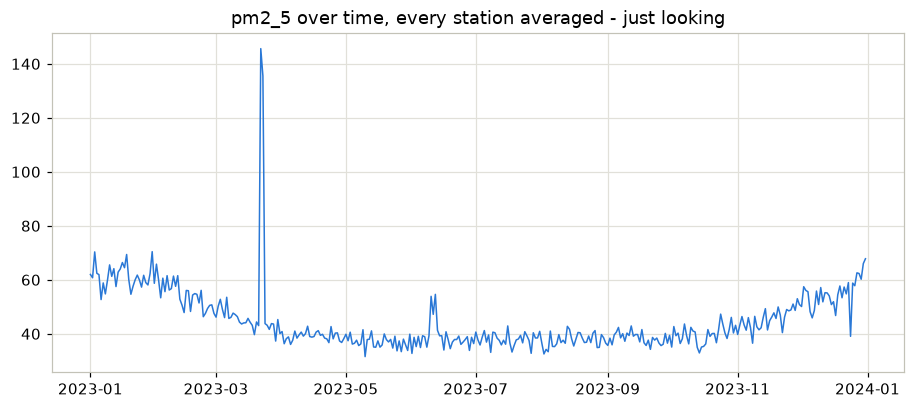

Two things jump out immediately, before any formal analysis:
  1. A slow rise-and-fall that looks seasonal.
  2. At least one sharp, short spike that does not fit that pattern.


In [3]:
# A first, deliberately unpolished look - this chart exists to think with, not to present.
fig, ax = plt.subplots(figsize=(10, 4))
daily_mean = aq.groupby("date")["pm2_5"].mean()
ax.plot(daily_mean.index, daily_mean.values, linewidth=1, color=PALETTE["blue"])
ax.set_title("pm2_5 over time, every station averaged - just looking")
plt.show()

print("Two things jump out immediately, before any formal analysis:")
print("  1. A slow rise-and-fall that looks seasonal.")
print("  2. At least one sharp, short spike that does not fit that pattern.")

Neither of those is a "finding" yet - a finding needs a number and a cause. But noticing them is what sends you toward the right next question, which is exactly the point of looking before you have a hypothesis.

---

## Asking good questions

"What is going on with air quality in Accra?" is curiosity, not a question you can answer. A question EDA can actually resolve is **specific** (names a variable), **comparative** (names what it is being compared against), and **answerable from the columns you have**.

| Vague | Specific and answerable |
|---|---|
| "Is pollution bad in Accra?" | "What fraction of station-days exceed the WHO 24-hour PM2.5 guideline of 15 ug/m3?" |
| "Does location matter?" | "How does mean PM2.5 differ between Roadside and Background stations?" |
| "Is there a pattern over the year?" | "Is mean PM2.5 higher in December-February than the rest of the year, and by how much?" |

In [4]:
pct_exceeding = (aq["pm2_5"] > WHO_24H_GUIDELINE).mean() * 100
print(f"Station-days exceeding the WHO 24-hour guideline ({WHO_24H_GUIDELINE} ug/m3): {pct_exceeding:.1f}%")

Station-days exceeding the WHO 24-hour guideline (15.0 ug/m3): 96.1%


That single number - computed the moment the vague question became a specific one - is already more useful than a page of charts built before you knew what to ask. Section 22a is entirely practice at this rewriting step.

---

## Univariate exploration: one variable at a time

Start with the shape of a single column before relating it to anything else. `.describe()` gives you five numbers; a histogram shows you the shape those five numbers were summarising.

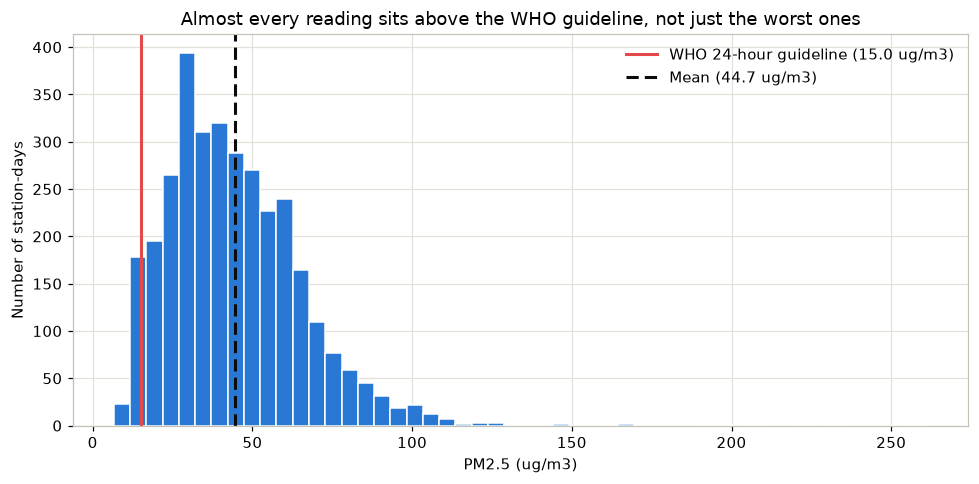

count    3278.0
mean       44.7
std        22.0
min         6.6
25%        28.9
50%        41.3
75%        57.4
max       261.3
Skew: 1.74 (right-skewed - a long tail of high readings pulls the mean above the median)


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(aq["pm2_5"].dropna(), bins=50, color=PALETTE["blue"], edgecolor="white")
ax.axvline(WHO_24H_GUIDELINE, color=PALETTE["red"], linewidth=2,
           label=f"WHO 24-hour guideline ({WHO_24H_GUIDELINE} ug/m3)")
ax.axvline(aq["pm2_5"].mean(), color=INK, linewidth=2, linestyle=(0, (4, 2)),
           label=f"Mean ({aq['pm2_5'].mean():.1f} ug/m3)")
ax.set_title("Almost every reading sits above the WHO guideline, not just the worst ones")
ax.set_xlabel("PM2.5 (ug/m3)")
ax.set_ylabel("Number of station-days")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(aq["pm2_5"].describe().round(1).to_string())
print(f"Skew: {aq['pm2_5'].skew():.2f} (right-skewed - a long tail of high readings pulls the mean above the median)")

The guideline line is doing real work here: without it, this is just "a right-skewed distribution." With it, the chart says something a reader can act on - the guideline is not a distant ceiling a few bad days bump into, it is close to where the *bulk* of the data already sits.

---

## Bivariate exploration: a pair of variables

Does PM2.5 depend on where you measure, or what the weather is doing? A box plot answers the first (a categorical pair); a scatter plot answers the second (a numeric pair).

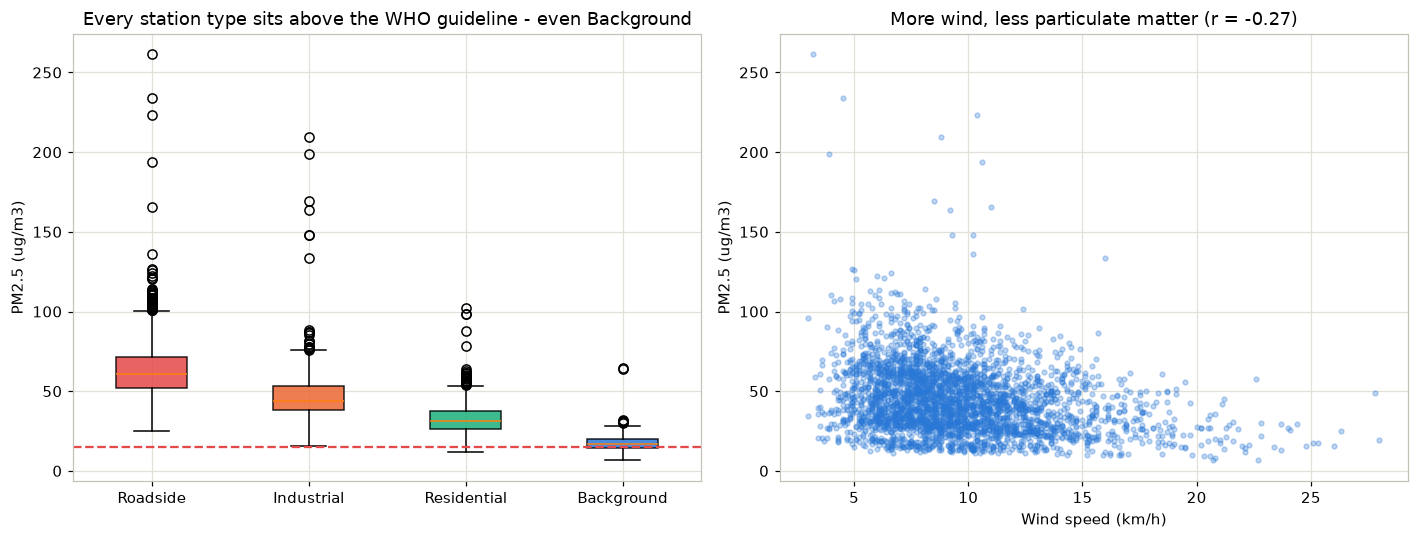

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

data = [aq.loc[aq["station_type"] == t, "pm2_5"].dropna() for t in STATION_TYPE_ORDER]
bp = axes[0].boxplot(data, tick_labels=STATION_TYPE_ORDER, patch_artist=True)
for patch, t in zip(bp["boxes"], STATION_TYPE_ORDER):
    patch.set_facecolor(STATION_TYPE_COLOR[t])
    patch.set_alpha(0.85)
axes[0].axhline(WHO_24H_GUIDELINE, color=PALETTE["red"], linewidth=1.5, linestyle="--")
axes[0].set_title("Every station type sits above the WHO guideline - even Background")
axes[0].set_ylabel("PM2.5 (ug/m3)")

axes[1].scatter(aq["wind_speed_kmh"], aq["pm2_5"], s=10, alpha=0.3, color=PALETTE["blue"])
r = aq["wind_speed_kmh"].corr(aq["pm2_5"])
axes[1].set_title(f"More wind, less particulate matter (r = {r:.2f})")
axes[1].set_xlabel("Wind speed (km/h)")
axes[1].set_ylabel("PM2.5 (ug/m3)")

fig.tight_layout()
plt.show()

Neither chart required a hypothesis going in - you plot the pair because it is plausible, then let the picture tell you whether it was worth plotting. Section 22c practices this on several more pairs, including two that turn out **not** to relate.

---

## Multivariate exploration: three or more at once

Station type and season each affect PM2.5 on their own. Plotting them together answers a sharper question: does the Harmattan bump hit every station type equally, or mostly the already-dirty ones?

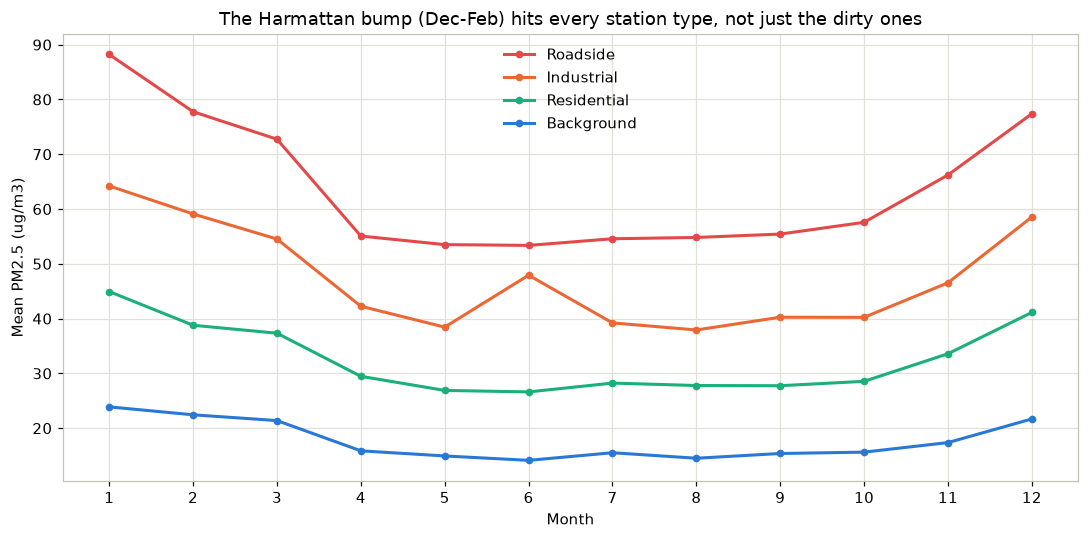

In [7]:
monthly_by_type = aq.groupby(["month", "station_type"])["pm2_5"].mean().unstack()[STATION_TYPE_ORDER]

fig, ax = plt.subplots(figsize=(10, 5))
for t in STATION_TYPE_ORDER:
    ax.plot(monthly_by_type.index, monthly_by_type[t], marker="o", markersize=4,
            linewidth=2, label=t, color=STATION_TYPE_COLOR[t])
ax.set_title("The Harmattan bump (Dec-Feb) hits every station type, not just the dirty ones")
ax.set_xlabel("Month")
ax.set_ylabel("Mean PM2.5 (ug/m3)")
ax.set_xticks(range(1, 13))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

That is a genuine multivariate finding: two variables (station type, month) combine *additively* rather than one cancelling the other out - Roadside in January is still worse than Background in January, and every type still rises together in Harmattan season. Section 22d goes further, with colour and facets as a third and fourth dimension on one figure.

---

## From patterns to insights

Not everything a scatter plot or a groupby surfaces is worth reporting. Three checks separate a real insight from a false lead:

1. **Sample size.** A dramatic-looking average from three data points is not a pattern - it is three data points.
2. **Correlation versus shared cause.** `pm2_5` and `pm10` correlate at r = 0.99 - but that is because they are two measurements of the same airborne dust, not because one causes the other. A more interesting case: `pm2_5` and `no2` correlate at r = 0.66, not because particulate matter causes nitrogen dioxide, but because both are elevated by the same thing - traffic and industrial activity at Roadside and Industrial stations.
3. **Interesting versus important.** A single extreme day is interesting. Whether it changes what anyone should *do* is a separate question - and answering it usually means finding out whether it was a one-off or the start of a pattern.

In [8]:
print("Three correlations with very different explanations:")
print(f"  pm2_5 vs pm10: r = {aq['pm2_5'].corr(aq['pm10']):.2f}  (same phenomenon, measured two ways)")
print(f"  pm2_5 vs no2:  r = {aq['pm2_5'].corr(aq['no2']):.2f}  (shared cause: traffic and industry)")
print(f"  pm2_5 vs temperature: r = {aq['pm2_5'].corr(aq['temperature_c']):.2f}  (both track the dry season)")

Three correlations with very different explanations:
  pm2_5 vs pm10: r = 0.99  (same phenomenon, measured two ways)
  pm2_5 vs no2:  r = 0.66  (shared cause: traffic and industry)
  pm2_5 vs temperature: r = 0.22  (both track the dry season)


None of those three numbers is wrong. All three would mislead a reader if reported as "X relates to Y" without the explanation attached. Section 22e practices exactly this: given a candidate finding, decide whether it survives these three checks before it goes in a report.

---

## Writing the wrangling report

Switching datasets here, deliberately: a wrangling report documents work you actually did, and the work you did was Topic 20's retail wrangling, not this lesson's air-quality exploration.

A wrangling report is short (roughly 300-600 words), plain language, and answers exactly three questions: **what problems did you find, what did you do about them, and what should a reader not fully trust as a result?** It is not a code walkthrough - a reader who never sees your notebook should still understand what happened to the data before it reached them.

In [9]:
# The retail "2023 Trading Review" table from Topic 20 - used for the two
# report-writing sections later in this notebook, since a wrangling report and
# an insights report have to be about work you actually did.
def clean_region(series):
    return (series.str.strip().str.replace(r"\s+", " ", regex=True).str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    expected_rows = len(orders)
    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")
    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))
    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)
    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)
    if len(table) != expected_rows:
        raise ValueError("Row count changed during wrangling.")
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Retail analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")

Retail analysis table: 1200 rows x 23 columns


**A worked example**, built from Topic 20's real, known issues:

> **Wrangling report - 2023 Trading Review**
>
> The distributor's data arrived as six separate files - orders, customers, products, regions, and returns, plus a wide table of monthly targets. Joining them cleanly required fixing three problems first.
>
> The `region` field in the customer list had 47 different spellings of 16 real regions (extra spaces, inconsistent capitalisation, e.g. `"north east"` and `" North East"` for the same region). These were standardised before any join, because an unmatched region silently drops a customer's sales from every regional total.
>
> The product list contained one duplicated product ID, pointing at two different warehouses. Left in place, this would have doubled the sales rows for that product and overstated total revenue. The duplicate was removed, keeping the first listed warehouse.
>
> Finally, 27 of 1,200 orders (2.3%) referenced a customer ID that does not appear in the customer list. These orders could not be assigned a region and were kept - removing them would have understated revenue by GHS 9,090.87 - but they are flagged throughout, and anyone using regional totals should know that 27 orders are not in any region's figure.
>
> With those three fixes applied and checked (every join carries a row-count check that would fail loudly if a fix went wrong), the resulting table is reliable for regional, product, and time-based analysis, with the one stated exception above.

Notice what that example does *not* do: it does not show a single line of code, a column name like `validate="m:1"`, or a DataFrame shape. Every number in it is real, but every sentence is written for someone who has never opened Jupyter.

---

## Writing the act report

The second report answers a different question for a different reader: not "can I trust this data" but "what does it tell us, and so what." Data storytellers use a consistent shape for this: a **hook**, three to five **ranked insights** (each with one chart and a one-line caption that states the finding, not describes the chart), and a closing **so-what** - what should the reader do differently now.

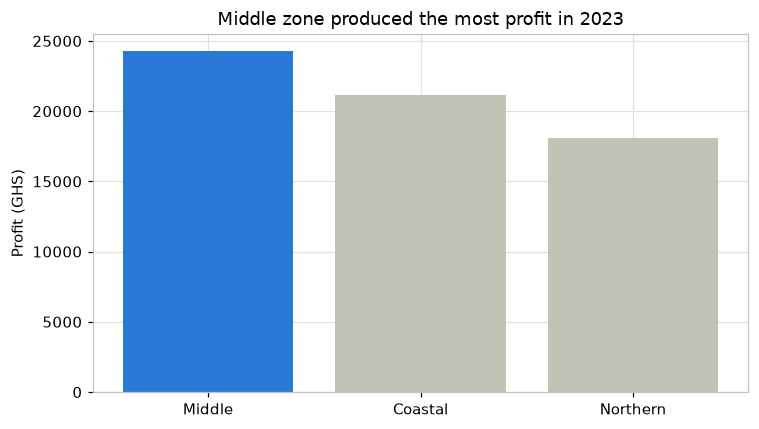

In [10]:
# One of the three to five insights a real act report would rank and include.
zone_profit = analysis.groupby("zone")["profit_ghs"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
colors = [PALETTE["blue"] if z == zone_profit.index[0] else MUTED for z in zone_profit.index]
ax.bar(zone_profit.index, zone_profit.values, color=colors)
ax.set_title(f"{zone_profit.index[0]} zone produced the most profit in 2023")
ax.set_ylabel("Profit (GHS)")
fig.tight_layout()
plt.show()

**A worked example** of the report this chart would sit inside, built from Topics 20-21's real findings:

> **The 2023 Trading Review, in brief**
>
> The distributor's 2023 revenue (GHS 230,001.08) was not spread evenly across the year, the map, or the product list - and three patterns matter more than the headline total.
>
> **1. Revenue jumped 55.6% in the last two months of the year.** November and December averaged GHS 27,300.78 a month, against GHS 17,539.95 for the rest of the year. Almost all of that jump came from the Middle zone alone, which suggests a seasonal or promotional effect worth planning stock around next year - not a broad trend across the whole business.
>
> **2. The best-margin zone is not the most profitable one.** Middle produced the most total profit (GHS 24,269.81), but Northern converted a larger share of its revenue into profit (29.7% margin against Middle's 28.2%). Growing Northern's volume, not just defending Middle's, may be the better lever.
>
> **3. A third of customers generate 69.2% of all profit.** The top profit tier - 70 of 209 customers - is worth a retention plan of its own; losing a handful of them would hurt more than the raw customer count suggests.
>
> **So what:** plan 2024 stock levels for a Nov-Dec surge concentrated in the Middle zone, investigate what is limiting Northern's volume given its strong margin, and build a specific retention plan for the top profit tier.
>
> *Limitations: this covers 2023 only - there is no prior year to confirm the Nov-Dec pattern repeats. Three customer-profit tiers were drawn from one year of data each.*

Compare this to the wrangling report above. Same underlying work, same author, completely different content: no mention of dirty region strings or duplicate keys - the reader of this report does not need to know the data was ever a problem, only what it now says.

---

## Put it together: one fact, two reports

The clearest way to see why audience changes everything is the same fact, written twice.

| | Wrangling report | Act report |
|---|---|---|
| About | 27 orphan orders with no matching customer | The same 27 orders, now part of the revenue total |
| Says | "27 of 1,200 orders reference an unknown customer and could not be assigned a region; they are kept but flagged." | "2023 revenue was GHS 230,001.08" *(the orphan orders are already inside this number - a reader of the act report does not need to know that)* |
| Reader needs to know | Exactly which numbers to double-check before relying on them | What the business should do next |
| Tone | Precise, hedged, specific about what is uncertain | Confident, narrative, built around a decision |

Neither version is dishonest. The wrangling report's job is to protect a reader who will build on your work; the act report's job is to move a reader who will act on your conclusion. Writing both, about the same work, is the actual skill this lesson is teaching - not writing charts, which Topic 21 already covered.

## Key takeaways

- **EDA is a loop, not a checklist**: question, look, visualize, answer or better question, repeat - and it ends when you have something worth writing down, not when you run out of charts to make.
- **A good EDA question is specific, comparative, and answerable** from the columns you actually have.
- **Univariate first, then bivariate, then multivariate** - look at one thing's shape before relating it to another, and relate two things before adding a third.
- **A strong correlation is not evidence of causation**, and is often two measurements of one underlying thing (`pm2_5` and `pm10`, r = 0.99) or two effects of a shared cause (`pm2_5` and `no2`, both driven by traffic and industry).
- **Sample size, shared causes, and "interesting vs. important" are the three checks** a pattern must survive before it becomes a reported finding.
- **A wrangling report** is short, plain-language, and exists to tell a reader exactly what to trust and what to double-check.
- **An act report** is a narrative built around ranked insights and a so-what, aimed at a reader who was never going to open the notebook.
- **The same fact can appear in both reports and sound completely different** - that difference is the skill, not an inconsistency.

## Further reading and the course path

### On exploratory data analysis
- [John Tukey, "Exploratory Data Analysis" (1977)](https://www.google.com/search?q=John+Tukey+Exploratory+Data+Analysis+1977) - the book that named this discipline
- [pandas: Essential basic functionality](https://pandas.pydata.org/docs/user_guide/basics.html)

### On writing about data
- [Cole Nussbaumer Knaflic, "Storytelling with Data"](https://www.storytellingwithdata.com/) - the act-report structure this lesson teaches comes from here
- [WHO global air quality guidelines (2021)](https://www.who.int/publications/i/item/9789240034228) - source of the PM2.5 thresholds used throughout this lesson

### Practice notebooks for this topic
- [22a - Asking good questions](topic22a_asking_good_questions.ipynb)
- [22b - Univariate exploration](topic22b_univariate_exploration.ipynb)
- [22c - Bivariate exploration](topic22c_bivariate_exploration.ipynb)
- [22d - Multivariate exploration](topic22d_multivariate_exploration.ipynb)
- [22e - From patterns to insights](topic22e_patterns_to_insights.ipynb)
- [22f - Writing the wrangling report](topic22f_writing_the_wrangling_report.ipynb)
- [22g - Writing the act report](topic22g_writing_the_act_report.ipynb)

### Assignment
- [Topic 22 assignment - Accra air-quality EDA](assignments/topic22_assignment_air_quality_eda.ipynb)

### Elsewhere in the course
- [Topic 20 - Data wrangling](../data_wrangling/topic20_data_wrangling.ipynb)
- [Topic 21 - Data visualization](../data_visualization/topic21_data_visualization.ipynb)
- [Submitting your work with GitHub](../data_analysis_process/topic19d_appendix_submitting_with_github.ipynb)